## EN3160 — Assignment 2
### Fitting and Alignment
**Student Name:** Deshan W. U.

**Index Number:** 230130E

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Question 1

In [4]:
# Load image
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None

# Get grayscale image
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

In [6]:
# Select range of sigma
sigma_values = np.linspace(1, 2, 4)
# Threhsold for blob detection
threshold = 0.35

# Store responses of each scale
blob_responses = []

for sigma in sigma_values:
    print(f"Processing scale with sigma = {sigma}")

    # Apply Gaussian blur
    gaussian_blur = cv.GaussianBlur(gray, (0, 0), sigma)
    # Compute Laplacian of Gaussian (LoG)
    laplacian = cv.Laplacian(gaussian_blur, cv.CV_64F)

    # Get absolute value
    blob_response = np.abs(laplacian)

    # Threshold the response and get contours
    mask = blob_response > threshold * blob_response.max()
    contours, _ = cv.findContours(mask.astype(np.uint8), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    # Draw contours as circles
    for contour in contours:
        if len(contour) >= 5:
            # Get the center and radius of the enclosing circle from contour
            (center_x, center_y), radius = cv.minEnclosingCircle(contour)
            # Convert to integers
            center = (int(center_x), int(center_y))
            radius = int(radius)
            blob_responses.append((center, radius, sigma))

Processing scale with sigma = 1.0
Processing scale with sigma = 1.3333333333333333
Processing scale with sigma = 1.6666666666666665
Processing scale with sigma = 2.0


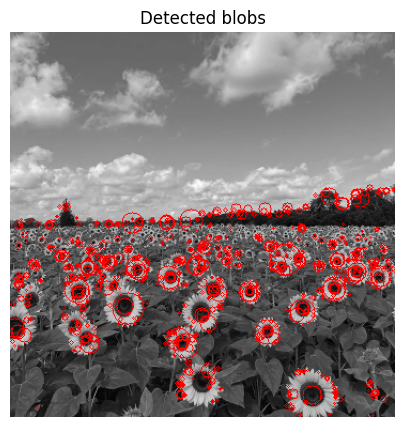

In [7]:
# Draw all detected circles with the specified line thickness
output = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
for blob in blob_responses:
    center, radius, _ = blob
    cv.circle(output, center, radius, (0, 0, 255), 1)

# Display the grayscale image with detected circles
plt.figure(figsize=(5, 5))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB), cmap='gray')
plt.axis('off')
plt.title('Detected blobs')
plt.show()

In [8]:
# Get largest circle
blobs_sorted = sorted(blob_responses, key=lambda x: x[1], reverse=True)
largest_blob = blobs_sorted[0]
center, radius, sigma = largest_blob

# Print largest circle details
print(f"Largest blob at : {center} with radius {radius} and sigma {sigma}")

Largest blob at : (110, 258) with radius 15 and sigma 2.0


The largest detected blob was located at **(110, 258)**, with a radius of **15 pixels** and a sigma value of **2.0 pixels**. The LoG-based blob detection was performed using four sigma values ranging from **1.0 to 2.0 pixels**: 1.00, 1.33, 1.67, and 2.00 pixels.


Question 2

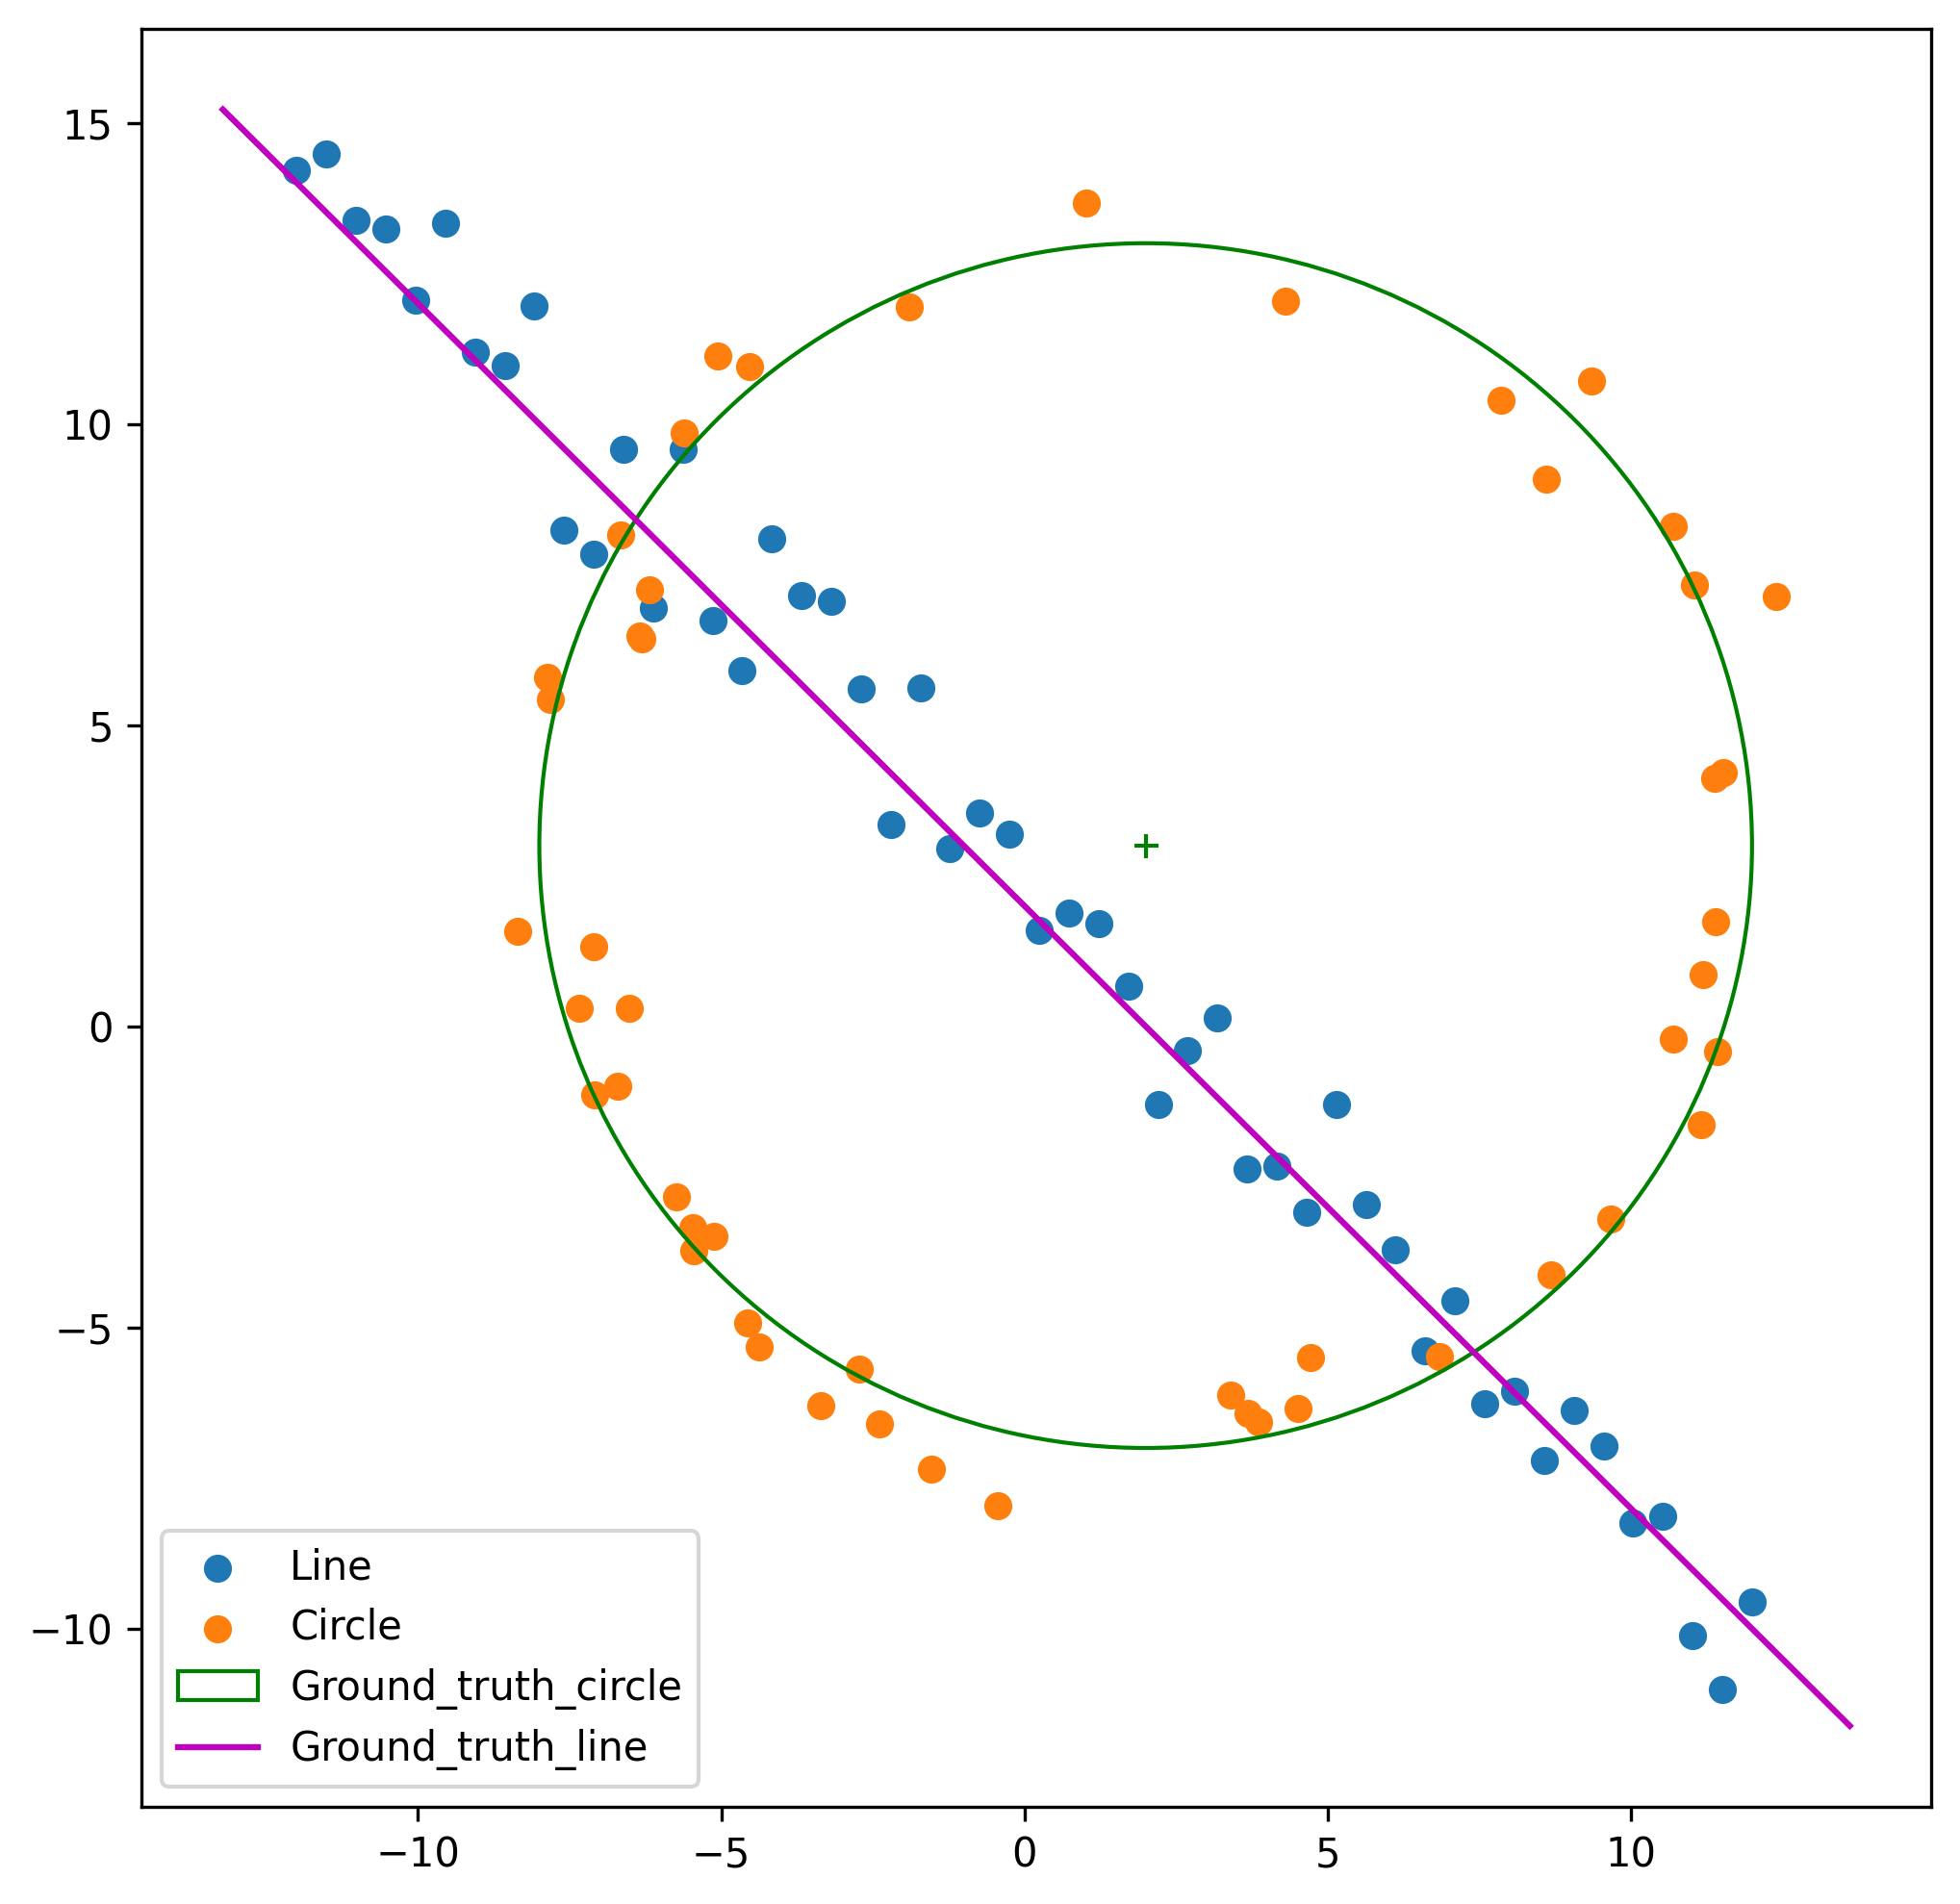

In [9]:
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)
N = 100
half_n = N//2

r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
X = np.vstack((X_circ, X_line))  # All points

fig, ax = plt.subplots(1,1, figsize=(8,8), dpi=300)
ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1], label='Circle')
circle_gt = plt.Circle((x0_gt,y0_gt), r, color='g', fill=False, label='Ground_truth_circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground_truth_line')
plt.legend()

part-a,b,c

Line   (a,b,d)  = [0.714 0.7   1.542]  inliers: 56
Circle (cx,cy,r) = [1.864 3.074 9.954]  inliers: 44


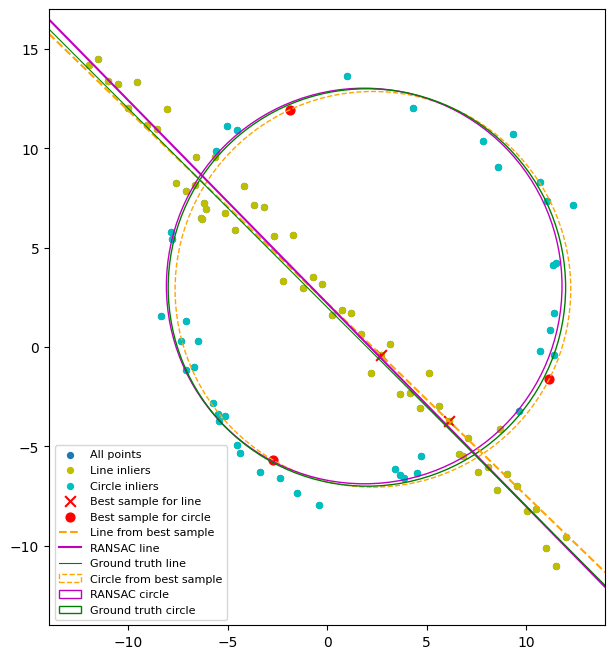

In [15]:
def line_fit(p, q):                      # (a,b,d), ||[a,b]|| = 1 by construction
    dx, dy = q - p; k = np.hypot(dx, dy)
    return np.array([dy/k, -dx/k, (dy*p[0] - dx*p[1])/k])
 
def line_err(h, P):                      # normal distance
    return np.abs(P @ h[:2] - h[2])
 
def line_refit(P, h0):                   
    return minimize(lambda h: np.sum((P @ h[:2] - h[2])**2), h0, method="SLSQP",
                    constraints={"type": "eq", "fun": lambda h: h[0]**2 + h[1]**2 - 1}).x
 
def circ_fit(p1, p2, p3):                # circle through 3 points (cx,cy,r)
    A = 2*np.array([p2 - p1, p3 - p1])
    if abs(np.linalg.det(A)) < 1e-9: return None
    c = np.linalg.solve(A, [p2@p2 - p1@p1, p3@p3 - p1@p1])
    return np.array([*c, np.linalg.norm(p1 - c)])
 
def circ_err(c, P):                      # radial error
    return np.abs(np.hypot(*(P - c[:2]).T) - c[2])
 
def circ_refit(P, c0):
    return minimize(lambda c: np.sum(circ_err(c, P)**2), c0, method="Nelder-Mead",
                    options={"xatol": 1e-8, "fatol": 1e-10, "maxiter": 5000}).x

def ransac(P, k, fit, err, thresh, min_inl, iters):
    best = None
    for _ in range(iters):
        idx = np.random.choice(len(P), k, replace=False)
        model = fit(*P[idx])
        if model is None: continue
        e = err(model, P); inl = e < thresh
        if inl.sum() >= min_inl:
            score = (inl.sum(), -e[inl].mean())
            if best is None or score > best[0]:
                best = (score, model, inl, idx)
    return best[1:]                  

l_model, l_inl, l_idx = ransac(X, 2, line_fit, line_err, 1.5, 30, 300)
rem = np.where(~l_inl)[0]
c_model, c_inl, c_idx = ransac(X[rem], 3, circ_fit, circ_err, 1.25, 30, 500)
l_best = line_refit(X[l_inl], l_model)
c_best = circ_refit(X[rem][c_inl], c_model)
print("Line   (a,b,d)  =", np.round(l_best, 3), " inliers:", l_inl.sum())
print("Circle (cx,cy,r) =", np.round(c_best, 3), " inliers:", c_inl.sum())
 

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, s=18, label="All points")
ax.scatter(*X[l_inl].T, c="y", s=18, label="Line inliers")
ax.scatter(*X[rem][c_inl].T, c="c", s=18, label="Circle inliers")
ax.scatter(*X[l_idx].T, c="r", marker="x", s=60, label="Best sample for line")
ax.scatter(*X[rem][c_idx].T, c="r", s=40, label="Best sample for circle")
xs = np.array([-14, 14.])
for h, kw in [(l_model, dict(c="orange", ls="--", label="Line from best sample")),
              (l_best, dict(c="m", label="RANSAC line"))]:
    ax.plot(xs, (h[2] - h[0]*xs)/h[1], **kw)
ax.plot(xs, m*xs + b, c="g", lw=0.8, label="Ground truth line")
for c, kw in [(c_model, dict(ec="orange", ls="--", label="Circle from best sample")),
              (c_best, dict(ec="m", label="RANSAC circle")),
              (np.array([x0_gt, y0_gt, r]), dict(ec="g", label="Ground truth circle"))]:
    ax.add_patch(plt.Circle(c[:2], c[2], fill=False, **kw))
ax.set_xlim(-14, 14); ax.set_ylim(-14, 17); ax.set_aspect("equal"); ax.legend(fontsize=8)
plt.show()

part-d

Fitting the circle first is less reliable. A circle model is more flexible than a line model, so a 3-point sample that falls mostly on the line can give a very large circle that explains many line points

Question 3

[1] a2images/galle_fort.jpg
H =
 [[ 7.424e-01 -2.490e-01  2.970e+02]
 [ 2.945e-01  3.054e-01  2.300e+02]
 [ 6.000e-04 -8.000e-04  1.000e+00]]


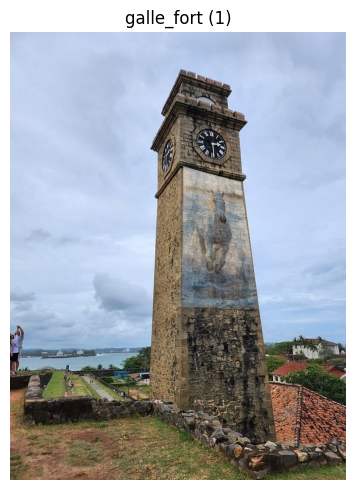

In [14]:
import os
def load(path):
    img = cv.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}  (cwd = {os.getcwd()})")
    return img


def click_points(img, n=4, title="Click 4 corners: TL, TR, BR, BL"):
    """Collect n clicks on an image with an OpenCV window."""
    pts, canvas = [], img.copy()

    def cb(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < n:
            pts.append((x, y))
            cv.circle(canvas, (x, y), 5, (0, 0, 255), -1)
            cv.putText(canvas, str(len(pts)), (x + 8, y - 8),
                       cv.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
            cv.imshow(title, canvas)

    cv.imshow(title, canvas)
    cv.setMouseCallback(title, cb)
    while len(pts) < n:
        if cv.waitKey(20) & 0xFF == 27:     
            break
    cv.waitKey(300)
    cv.destroyAllWindows()
    return np.array(pts, dtype=np.float32)


def overlay(arch, flag, dst_pts, alpha=0.6):
    """Warp `flag` onto the quadrilateral dst_pts (TL,TR,BR,BL) of `arch` and blend."""
    h, w = flag.shape[:2]
    src_pts = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], np.float32)
    H, _ = cv.findHomography(src_pts, dst_pts)         
    size = (arch.shape[1], arch.shape[0])
    warped = cv.warpPerspective(flag, H, size)
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size)[..., None] / 255.0
    out = arch * (1 - alpha * mask) + warped * (alpha * mask)
    return out.astype(np.uint8), H


if __name__ == "__main__":
    flag = load("a2images/horses.jpg")
    pairs = ["a2images/galle_fort.jpg"]  

    fig, axs = plt.subplots(1, len(pairs), figsize=(6 * len(pairs), 5))
    for i, (ax, path) in enumerate(zip(np.atleast_1d(axs), pairs), start=1):
        arch = load(path)
        pts = click_points(arch)
        out, H = overlay(arch, flag, pts)
        print(f"[{i}] {path}\nH =\n", np.round(H / H[2, 2], 4))
        name = os.path.splitext(os.path.basename(path))[0]
        cv.imwrite(f"result_{i}_{name}.jpg", out)       # saved in the current folder
        ax.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB)); ax.set_title(f"{name} ({i})"); ax.axis("off")
    plt.tight_layout(); plt.savefig("q3_results.png", dpi=150); plt.show()

Question 4

AAAA1.jpg: keypoints 2414/14272, ratio-test matches 51, RANSAC inliers 18


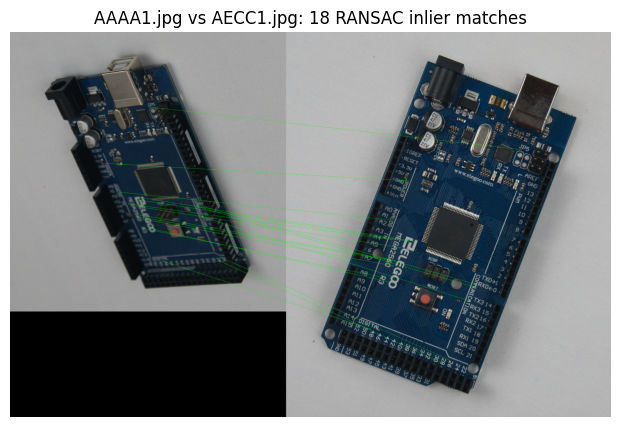

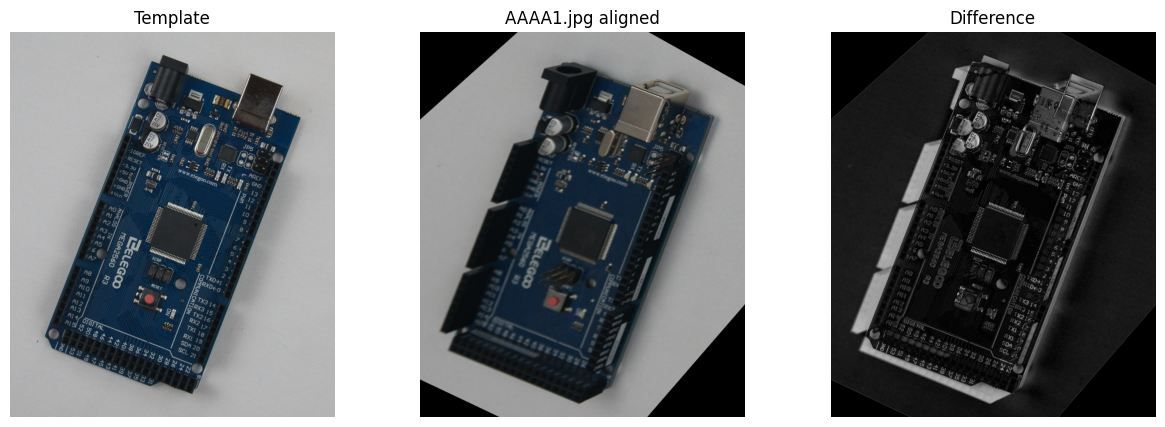

ADAD1.jpg: keypoints 8486/14272, ratio-test matches 369, RANSAC inliers 194


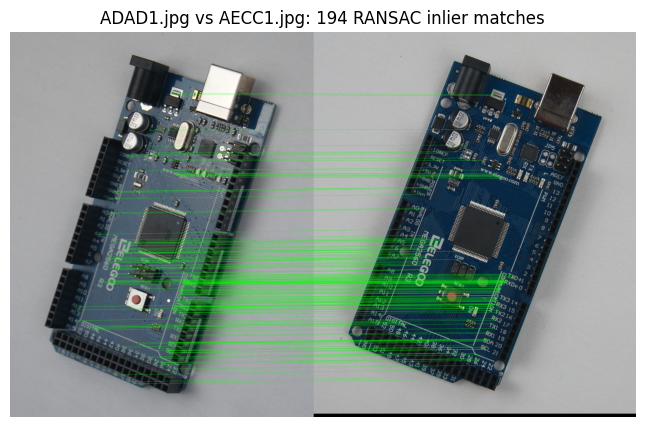

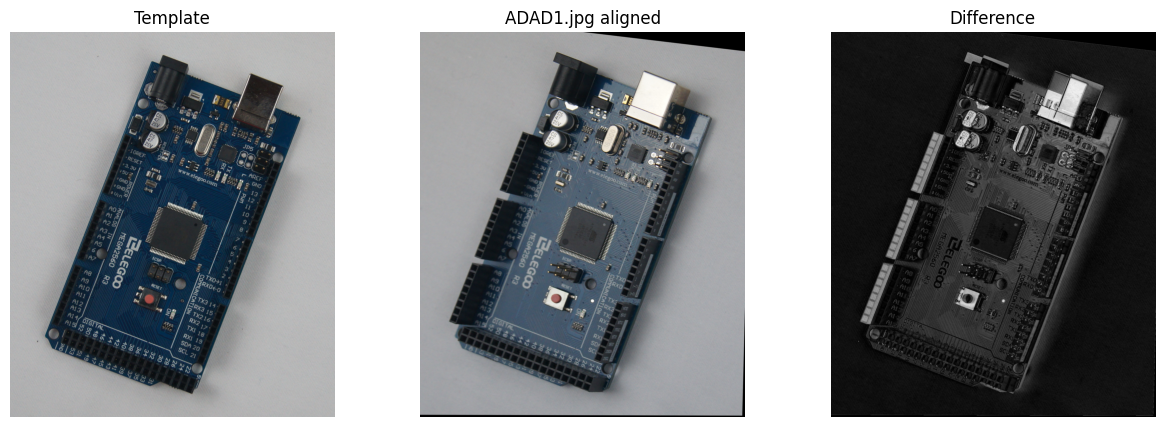

AECC2.jpg: keypoints 12315/14272, ratio-test matches 4322, RANSAC inliers 3847


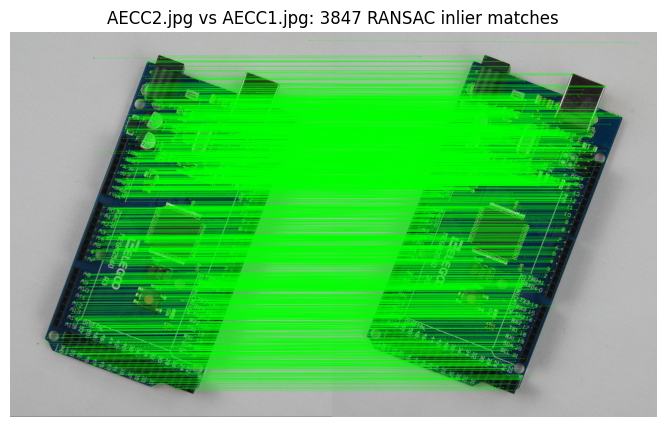

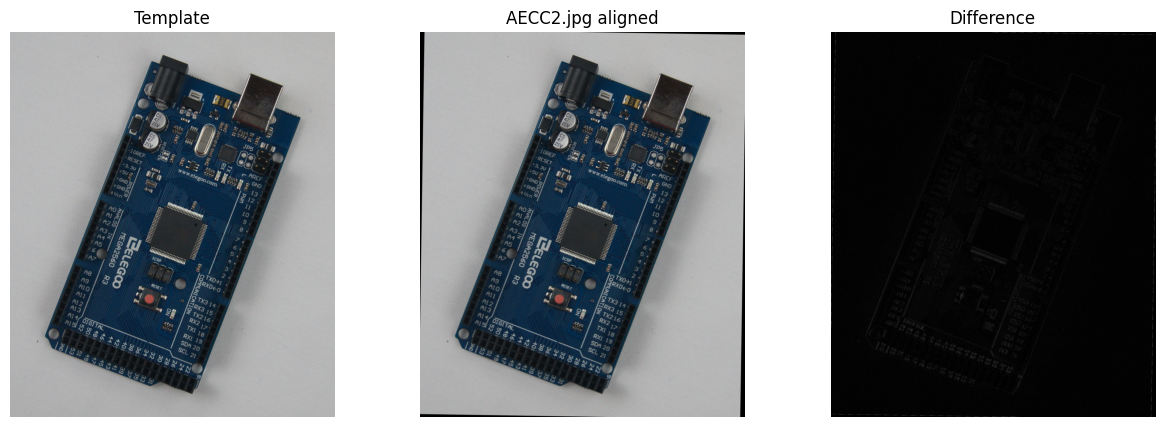

AECC3.jpg: keypoints 15198/14272, ratio-test matches 5629, RANSAC inliers 5006


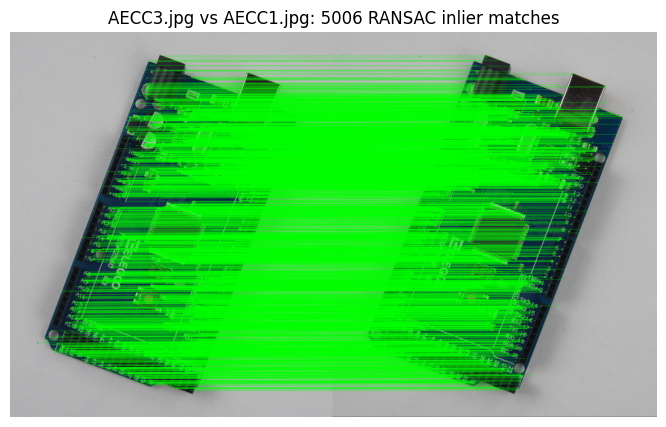

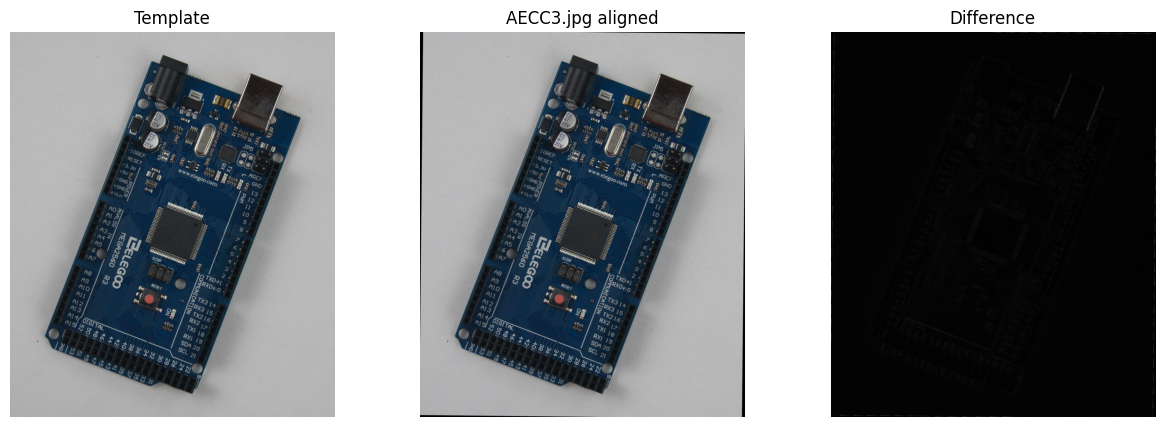

AECC4.jpg: keypoints 11610/14272, ratio-test matches 3830, RANSAC inliers 3402


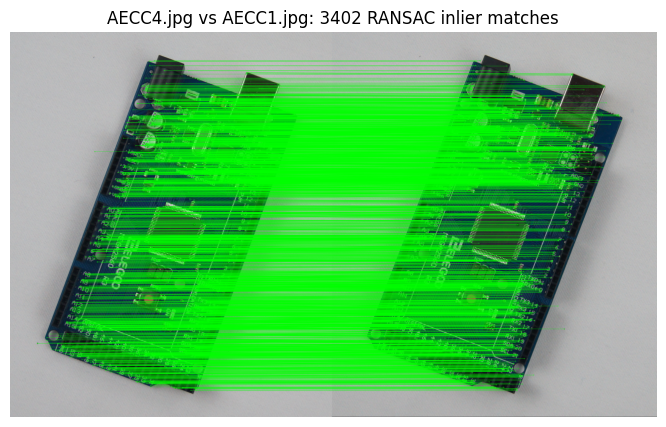

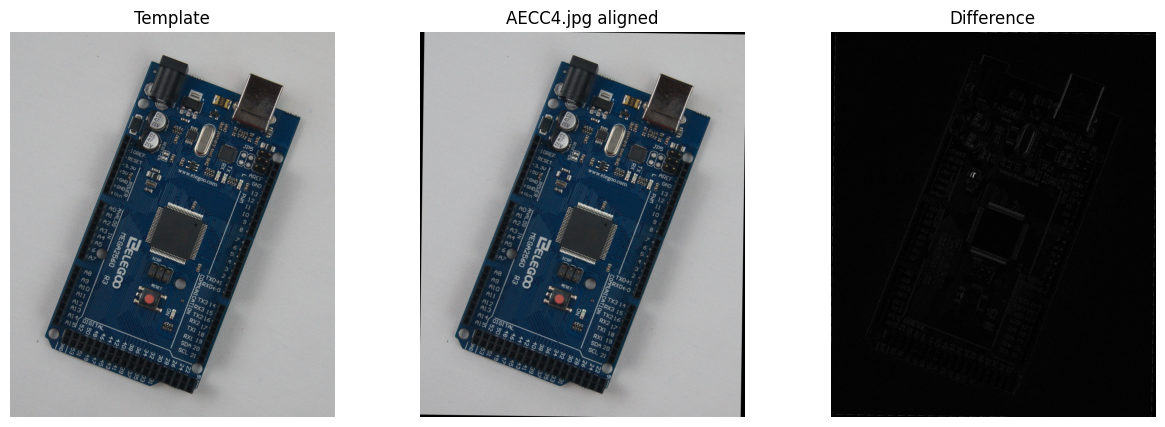

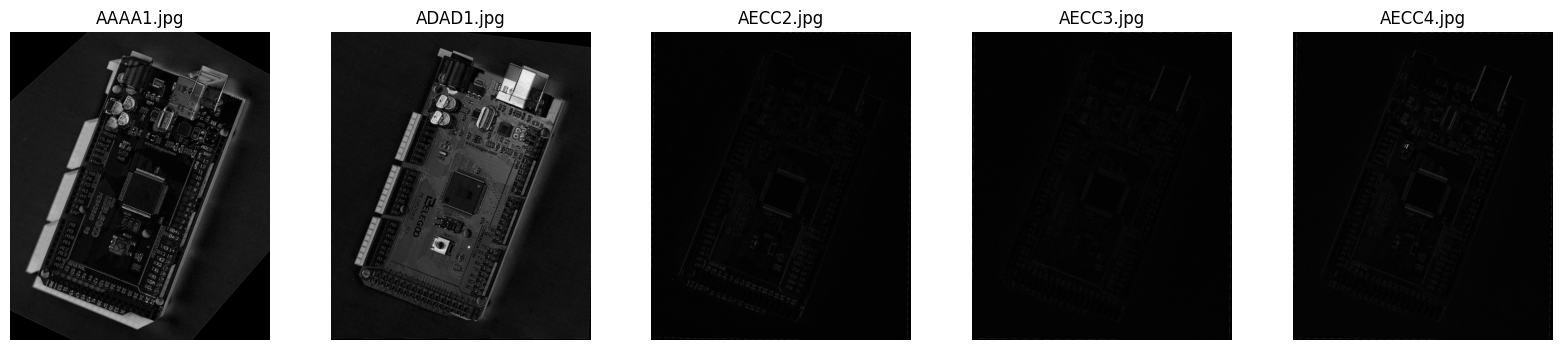

In [15]:
DIR = "a2images/pcbs"
TEMPLATE = "AECC1.jpg"
OTHERS = ["AAAA1.jpg", "ADAD1.jpg", "AECC2.jpg", "AECC3.jpg", "AECC4.jpg"]
OUT = "q4_outputs"
os.makedirs(OUT, exist_ok=True)


def load(path):
    img = cv.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}  (cwd = {os.getcwd()})")
    return img


sift = cv.SIFT_create()                                   # (a) SIFT detector/descriptor


def align(template, img, ratio=0.75, ransac_thresh=5.0):
    g_t = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
    g_i = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    kp_t, des_t = sift.detectAndCompute(g_t, None)        # (a) features
    kp_i, des_i = sift.detectAndCompute(g_i, None)

    bf = cv.BFMatcher()                                   # (b) brute-force matching
    knn = bf.knnMatch(des_i, des_t, k=2)
    good = [m for m, n in knn if m.distance < ratio * n.distance]   # Lowe ratio test

    src = np.float32([kp_i[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, ransac_thresh) 
    inl = mask.ravel().astype(bool)

    h, w = template.shape[:2]
    aligned = cv.warpPerspective(img, H, (w, h))          # (c) warp onto the template
    valid = cv.warpPerspective(np.full(g_i.shape, 255, np.uint8), H, (w, h)) > 0
    diff = cv.absdiff(cv.cvtColor(aligned, cv.COLOR_BGR2GRAY), g_t)
    diff[~valid] = 0                                      # ignore area outside the warped image

    vis = cv.drawMatches(img, kp_i, template, kp_t, [m for m, k in zip(good, inl) if k],
                         None, matchColor=(0, 255, 0),
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return aligned, diff, vis, H, len(kp_i), len(kp_t), len(good), int(inl.sum())


if __name__ == "__main__":
    template = load(os.path.join(DIR, TEMPLATE))
    diffs = {}
    for name in OTHERS:                                   # (d) all PCB images
        img = load(os.path.join(DIR, name))
        aligned, diff, vis, H, n_i, n_t, n_good, n_inl = align(template, img)
        diffs[name] = diff
        print(f"{name}: keypoints {n_i}/{n_t}, ratio-test matches {n_good}, RANSAC inliers {n_inl}")

        plt.figure(figsize=(12, 5))                       # (b) matches
        plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB)); plt.axis("off")
        plt.title(f"{name} vs {TEMPLATE}: {n_inl} RANSAC inlier matches")
        plt.savefig(f"{OUT}/matches_{name[:-4]}.png", dpi=150, bbox_inches="tight"); plt.show()

        fig, ax = plt.subplots(1, 3, figsize=(15, 5))     # (c) aligned + difference
        ax[0].imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB)); ax[0].set_title("Template")
        ax[1].imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB)); ax[1].set_title(f"{name} aligned")
        ax[2].imshow(diff, cmap="gray"); ax[2].set_title("Difference")
        for a in ax: a.axis("off")
        plt.savefig(f"{OUT}/diff_{name[:-4]}.png", dpi=150, bbox_inches="tight"); plt.show()

    # (d) summary of all difference images
    fig, axs = plt.subplots(1, len(diffs), figsize=(4 * len(diffs), 4))
    for a, (name, d) in zip(np.atleast_1d(axs), diffs.items()):
        a.imshow(d, cmap="gray"); a.set_title(name); a.axis("off")
    plt.savefig(f"{OUT}/all_differences.png", dpi=150, bbox_inches="tight"); plt.show()